# Estimación de la posición: de nueve pseudodistancias a x, y, z y el reloj

Este cuaderno acompaña la unidad de *estimación de la posición*. Toma las pseudodistancias reales de la estación **KOUR** (Bogotá, red IGS, NASA/JPL) del 15 de septiembre de 2026 y calcula, paso a paso, dónde está el receptor: linealización, mínimos cuadrados, iteración, ponderación, covarianza y DOP. Como la posición verdadera de KOUR se conoce, cada resultado se puede comparar con ella.

El archivo `data/KOUR_20260915_gps.csv` tiene una fila por época y satélite GPS: `P1` (pseudodistancia en L1, m), `xs, ys, zs` (posición del satélite al emitir, m), `dts` (corrección del reloj del satélite, s), `el`, `az` (elevación y acimut desde KOUR, grados), más `P2`, `L1`, `S1` que aquí no se usan.

Cada sección sigue el mismo patrón: una definición breve, el cálculo con los datos, y una figura o tabla.

In [31]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
AZUL, ROJO, VERDE, GRIS, NARANJA = "#1F3864", "#9C0006", "#375623", "#7F7F7F", "#C55A11"

# velocidad de la luz en el vacío (m/s): valor exacto, porque define el metro en el SI
C = 299_792_458.0

# el dato común: una fila por época y satélite GPS
D = pd.read_csv("data/bogt_20260915_gps.csv", parse_dates=["t"])

# la posición publicada de la estación (X, Y, Z geocéntricas, en metros)
lineas = open("data/bogt_20260915_estacion.txt").read().splitlines()[1:]
est = dict(linea.split() for linea in lineas)
rx = np.array([float(est["X"]), float(est["Y"]), float(est["Z"])])

print("filas:", len(D), "| épocas:", D.t.nunique(), "| satélites distintos:", D.sv.nunique())
print("KOUR (X, Y, Z) =", rx)
D.head()

filas: 27312 | épocas: 2880 | satélites distintos: 32
KOUR (X, Y, Z) = [ 1744399.0397 -6116037.5577   512731.7532]


,t,sv,P1,P2,L1,S1,xs,ys,zs,dts,el,az
0,2026-09-15,G01,2.286695e+07,2.286696e+07,1.201667e+08,43.00,7.296331e+06,-1.744863e+07,-1.861866e+07,0.000172,28.206252,173.658860
1,2026-09-15,G02,2.136431e+07,2.136431e+07,1.122703e+08,46.00,1.350578e+07,-1.873477e+07,-1.218097e+07,0.000176,41.829773,150.537422
2,2026-09-15,G03,2.381813e+07,2.381813e+07,1.251650e+08,41.25,-4.519559e+06,-1.798759e+07,-1.925986e+07,0.000267,19.727789,204.363168
3,2026-09-15,G04,2.035627e+07,2.035627e+07,1.069731e+08,48.50,2.989410e+05,-2.631631e+07,2.755613e+06,0.000065,70.010475,275.735921
4,2026-09-15,G08,2.000519e+07,2.000520e+07,1.051282e+08,50.50,5.720878e+06,-2.429087e+07,8.143931e+06,0.000346,72.001567,349.230971


## 1. El problema: nueve ecuaciones, cuatro incógnitas

> **Ecuación de la pseudodistancia** para el satélite $i$, con la medida ya corregida del reloj del satélite:
> $$\rho_i + c\,\delta t^i = \underbrace{\sqrt{(x - x^i)^2 + (y - y^i)^2 + (z - z^i)^2}}_{r_i(x,y,z)} + \underbrace{c\,\delta t_R}_{b} + \varepsilon_i$$
> Conocidos: $\rho_i$, $x^i, y^i, z^i$, $\delta t^i$. Incógnitas: $x, y, z$ (m) y $b = c\,\delta t_R$, el error del reloj del receptor en metros. $\varepsilon_i$: lo que no se modela.

La raíz cuadrada impide despejar; y con nueve ecuaciones y ruido no existe un $(x, y, z, b)$ que las cumpla todas. Hace falta (1) un método que se acerque a la solución paso a paso y (2) un criterio para elegir la «mejor» cuando ninguna es exacta.

In [32]:
t0 = pd.Timestamp("2026-09-15 12:00:00")
ep = D[D.t == t0].sort_values("sv").reset_index(drop=True)

S = ep[["xs", "ys", "zs"]].values           # posiciones de los satélites al emitir: matriz n × 3 (m)
P = ep.P1.values + C * ep.dts.values         # pseudodistancias ya corregidas del reloj del satélite (m)
n = len(P)
print("satélites:", list(ep.sv), "| n =", n)

tabla = ep[["sv", "el", "P1", "dts"]].copy()
tabla["P_corregida"] = P
tabla.round(3)

satélites: ['G05', 'G11', 'G12', 'G13', 'G15', 'G20', 'G24', 'G25', 'G29'] | n = 9


,sv,el,P1,dts,P_corregida
0,G05,22.068,2.342492e+07,-0.000,2.335393e+07
1,G11,29.830,2.281779e+07,-0.000,2.275507e+07
2,G12,22.278,2.386724e+07,-0.001,2.368675e+07
3,G13,19.560,2.365321e+07,0.000,2.378587e+07
4,G15,68.513,2.022137e+07,0.000,2.035474e+07
5,G20,46.896,2.149660e+07,0.000,2.158236e+07
6,G24,40.558,2.206766e+07,0.000,2.213020e+07
7,G25,17.461,2.412188e+07,0.000,2.423833e+07
8,G29,47.305,2.149618e+07,-0.000,2.142342e+07


## 2. Empezar sin saber nada: el receptor en el centro de la Tierra

Supóngase que el receptor arranca en $(0, 0, 0)$ con reloj perfecto ($b = 0$). Desde ahí la distancia «predicha» a cada satélite es su radio orbital. La diferencia entre lo medido y lo predicho —miles de kilómetros— es la información con la que se trabaja: dice hacia dónde y cuánto mover la posición supuesta.

In [33]:
x0 = np.zeros(4)                                  # posición supuesta (x, y, z) = (0, 0, 0) y reloj b = 0
r0 = np.linalg.norm(S - x0[:3], axis=1)          # distancia de cada satélite a la posición supuesta
dP = P - (r0 + x0[3])                             # lo que la posición supuesta NO explica de cada medida

pd.DataFrame({"sv": ep.sv,
              "medida (km)": P / 1e3,
              "predicha desde (0,0,0) (km)": r0 / 1e3,
              "diferencia (km)": dP / 1e3}).round(1)

,sv,medida (km),"predicha desde (0,0,0) (km)",diferencia (km)
0,G05,23353.9,26418.7,-3064.7
1,G11,22755.1,26513.3,-3758.2
2,G12,23686.8,26767.7,-3080.9
3,G13,23785.9,26612.9,-2827.1
4,G15,20354.7,26394.8,-6040.1
5,G20,21582.4,26598.9,-5016.5
6,G24,22130.2,26724.4,-4594.2
7,G25,24238.3,26853.6,-2615.3
8,G29,21423.4,26467.8,-5044.4


## 3. La idea en una dimensión: Newton-Raphson

> **Newton-Raphson** — para hallar $x$ tal que $f(x) = 0$, desde una estimación $x_k$ se sustituye la curva por su recta tangente y se toma el cruce de la tangente con el eje como estimación siguiente:
> $$x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)}$$

Cada paso se acerca más a la raíz y aproximadamente duplica el número de cifras correctas. Con cuatro incógnitas la «tangente» es un plano en cuatro dimensiones, pero la mecánica es idéntica: **evaluar, derivar, corregir, repetir**.

In [34]:
def f(x):  return x**3 - x - 1        # la función cuya raíz se busca
def df(x): return 3 * x**2 - 1        # su derivada

xk = 1.0                              # estimación inicial
filas = []
for k in range(1, 6):
    x_siguiente = xk - f(xk) / df(xk)                    # el paso de Newton-Raphson
    filas.append(dict(k=k, x_k=xk, f=f(xk), df=df(xk), x_siguiente=x_siguiente))
    xk = x_siguiente
pd.DataFrame(filas).round(7)

,k,x_k,f,df,x_siguiente
0,1,1.000000,-1.000000e+00,2.000000,1.500000
1,2,1.500000,8.750000e-01,5.750000,1.347826
2,3,1.347826,1.006822e-01,4.449905,1.325200
3,4,1.325200,2.058400e-03,4.268468,1.324718
4,5,1.324718,9.000000e-07,4.264635,1.324718


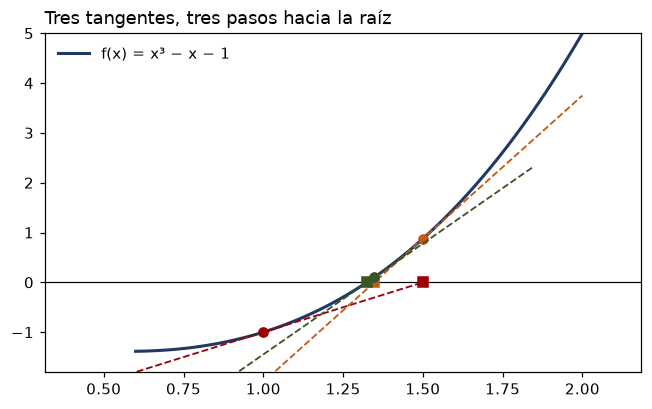

In [35]:
xs = np.linspace(0.6, 2.1, 300)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs, f(xs), color=AZUL, lw=2, label="f(x) = x³ − x − 1")
ax.axhline(0, color="k", lw=0.8)

xk = 1.0
for color in [ROJO, NARANJA, VERDE]:
    xt = np.linspace(xk - 0.6, xk + 0.5, 50)
    ax.plot(xt, f(xk) + df(xk) * (xt - xk), "--", color=color, lw=1.2)   # la recta tangente en xk
    ax.plot(xk, f(xk), "o", color=color)                                  # el punto sobre la curva
    xk = xk - f(xk) / df(xk)                                              # el cruce de la tangente con el eje
    ax.plot(xk, 0, "s", color=color)
ax.set_ylim(-1.8, 5)
ax.legend(frameon=False)
ax.set_title("Tres tangentes, tres pasos hacia la raíz", loc="left");

## 4. Linealizar: el vector unitario hacia el satélite

> Si el receptor está en una posición aproximada $\mathbf{x}_0$ y la verdadera es $\mathbf{x}_0 + \Delta\mathbf{x}$, la distancia a un satélite $\mathbf{s}$ desarrollada en **serie de Taylor a primer orden** es
> $$r(\mathbf{x}) \approx r_0 - \mathbf{e}\cdot\Delta\mathbf{x}, \qquad \mathbf{e} = \frac{\mathbf{s} - \mathbf{x}_0}{r_0}$$
> $\mathbf{e}$ es el **vector unitario** del receptor hacia el satélite; sus componentes son las derivadas de la distancia respecto a $x, y, z$ (con signo menos). Moverse 1 m hacia el satélite acorta la distancia 1 m; moverse en perpendicular no la cambia.

In [36]:
def vectores_unitarios(x, S):
    """Desde la posición x = (x, y, z, b): distancias r a cada satélite y vectores unitarios e hacia cada uno."""
    r = np.linalg.norm(S - x[:3], axis=1)   # distancia a cada satélite (n)
    e = (S - x[:3]) / r[:, None]             # (satélite − receptor) / distancia: longitud 1 (n × 3)
    return e, r

# para ver los números, desde la posición publicada de BOGT (con b = 0)
e, r = vectores_unitarios(np.r_[rx, 0.0], S)
k15 = list(ep.sv).index("G15")
print("e(G15) =", e[k15].round(4), "| longitud =", np.linalg.norm(e[k15]).round(6), "| r0 =", f"{r[k15]:,.3f} m".replace(",", " "))

e(G15) = [ 0.0028 -0.9416  0.3368] | longitud = 1.0 | r0 = 20 354 736.807 m


## 5. Una fila por satélite: la matriz de diseño

Sustituyendo la linealización en la ecuación de cada satélite y pasando lo conocido a la izquierda:
$$\underbrace{\rho_i + c\,\delta t^i - r_{0,i} - b_0}_{\Delta\rho_i} = -e_{x,i}\,\Delta x - e_{y,i}\,\Delta y - e_{z,i}\,\Delta z + \Delta b$$
> **Matriz de diseño $\mathbf{A}$** ($n \times 4$) — una fila por satélite: las tres componentes de su vector unitario con signo menos y un 1 para el reloj. El sistema lineal es $\mathbf{A}\,\Delta\mathbf{x} = \Delta\boldsymbol{\rho}$, con incógnitas las **correcciones** $\Delta x, \Delta y, \Delta z, \Delta b$.

In [37]:
def diseno(x, S, P):
    """Matriz de diseño A (n × 4) y vector de diferencias dP (n) en la posición aproximada x = (x, y, z, b).
    Fila i de A: (−e_x, −e_y, −e_z, 1). dP_i: pseudodistancia corregida menos lo que explica x."""
    e, r = vectores_unitarios(x, S)
    A = np.hstack([-e, np.ones((len(P), 1))])
    dP = P - (r + x[3])
    return A, dP

A, dP = diseno(np.r_[rx, 0.0], S, P)
pd.DataFrame(A, index=ep.sv, columns=["−e_x", "−e_y", "−e_z", "1"]).round(4)

,−e_x,−e_y,−e_z,1
sv,,,,
G05,-0.3480,0.2157,-0.9123,1.0
G11,-0.9700,0.2430,0.0078,1.0
G12,0.1292,0.5044,0.8537,1.0
G13,0.0668,0.4438,0.8936,1.0
G15,-0.0028,0.9416,-0.3368,1.0
G20,-0.4289,0.5810,-0.6917,1.0
G24,-0.3821,0.6267,0.6791,1.0
G25,0.6069,0.5357,0.5872,1.0
G29,0.3188,0.8172,-0.4802,1.0


## 6. Mínimos cuadrados: el criterio y las ecuaciones normales

> **Sistema sobredeterminado** — más ecuaciones que incógnitas: en general ninguna $\Delta\mathbf{x}$ cumple todas. Para cada satélite queda un **residuo** $v_i = \Delta\rho_i - (\mathbf{A}\Delta\mathbf{x})_i$.
>
> **Mínimos cuadrados** (Legendre 1805, Gauss 1809) — elegir la $\Delta\mathbf{x}$ que hace mínima $\sum v_i^2$. Derivando e igualando a cero salen las **ecuaciones normales**:
> $$(\mathbf{A}^{\top}\mathbf{A})\,\Delta\mathbf{x} = \mathbf{A}^{\top}\Delta\boldsymbol{\rho} \quad\Rightarrow\quad \Delta\mathbf{x} = (\mathbf{A}^{\top}\mathbf{A})^{-1}\mathbf{A}^{\top}\Delta\boldsymbol{\rho}$$

La suma de cuadrados es una parábola en cada incógnita; el mínimo es donde la pendiente es cero.

In [38]:
def paso_minimos_cuadrados(A, dP, W=None):
    """Resuelve las ecuaciones normales (AᵀWA) Δx = AᵀW dP. Sin W, todos los pesos valen 1.
    Devuelve la corrección Δx, la matriz normal N = AᵀWA y su inversa (la matriz cofactor Q)."""
    if W is None:
        W = np.eye(len(dP))
    N = A.T @ W @ A
    dx = np.linalg.solve(N, A.T @ W @ dP)
    return dx, N, np.linalg.inv(N)

dx, N, Q = paso_minimos_cuadrados(A, dP)
print("AᵀA =\n", N.round(3))
print("\ncorrección Δx = (Δx, Δy, Δz, Δb) en metros:", dx.round(3))

AᵀA =
 [[ 1.883 -0.122  0.721 -1.01 ]
 [-0.122  3.129  0.261  4.909]
 [ 0.721  0.261  3.988  0.6  ]
 [-1.01   4.909  0.6    9.   ]]

corrección Δx = (Δx, Δy, Δz, Δb) en metros: [  3.871 -10.574   1.818  12.998]


## 7. Iterar: linealizar, resolver, corregir, repetir

Se parte del centro de la Tierra. En cada iteración se linealiza en la posición supuesta, se resuelven las ecuaciones normales y se suma la corrección. Se detiene cuando la corrección es despreciable (aquí, menor que 0,1 mm). Este esquema —Newton-Raphson aplicado a mínimos cuadrados— se llama **Gauss-Newton**.

In [39]:
def resolver(S, P, x0=None, W=None, tol=1e-4, maxit=20):
    """Mínimos cuadrados iterados (Gauss-Newton) para la posición del receptor.
    S: posiciones de los satélites (n × 3) · P: pseudodistancias corregidas del reloj del satélite (n)
    x0: posición inicial (x, y, z, b); por defecto el centro de la Tierra · W: matriz de pesos (n × n)
    tol: se detiene cuando la corrección es menor (m) · Devuelve x, A final, residuos v, Q = (AᵀWA)⁻¹ y el historial."""
    x = np.zeros(4) if x0 is None else np.array(x0, float)
    if W is None:
        W = np.eye(len(P))
    historial = []
    for k in range(1, maxit + 1):
        A, dP = diseno(x, S, P)                            # 1. linealizar en la posición actual
        dx, N, Q = paso_minimos_cuadrados(A, dP, W)         # 2. resolver las ecuaciones normales
        historial.append(dict(iteracion=k, norma_dx=np.linalg.norm(dx[:3]), rms_dP=np.sqrt(np.mean(dP**2))))
        x = x + dx                                          # 3. corregir
        if np.linalg.norm(dx) < tol:                        # 4. repetir hasta que la corrección sea despreciable
            break
    A, v = diseno(x, S, P)                                  # residuos finales: lo que la solución no explica
    Q = np.linalg.inv(A.T @ W @ A)
    return x, A, v, Q, pd.DataFrame(historial)

x, A, v, Q, hist = resolver(S, P)
print("solución (x, y, z, b) =", x.round(3))
print("posición publicada    =", rx.round(3))
print("diferencia (m)        =", (x[:3] - rx).round(3))
hist.round(4)

solución (x, y, z, b) = [ 1.74440291e+06 -6.11604813e+06  5.12733571e+05  1.29980000e+01]
posición publicada    = [ 1744399.04  -6116037.558   512731.753]
diferencia (m)        = [  3.871 -10.574   1.818]


,iteracion,norma_dx,rms_dP
0,1,7.580704e+06,4.163893e+06
1,2,1.168265e+06,6.876862e+05
2,3,3.244160e+04,2.155425e+04
3,4,2.557130e+01,1.596620e+01
4,5,0.000000e+00,6.098000e-01


desde centro de la Tierra   : 5 iteraciones, misma solución a 0.0000 m
desde Medellín aproximado   : 4 iteraciones, misma solución a 0.0000 m
desde antípoda de Bogotá    : 6 iteraciones, misma solución a 0.0000 m


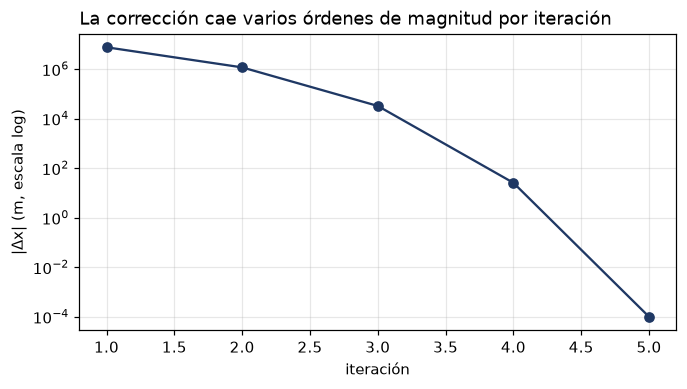

In [40]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(hist.iteracion, hist.norma_dx.clip(1e-4), "o-", color=AZUL)
ax.set_xlabel("iteración")
ax.set_ylabel("|Δx| (m, escala log)")
ax.grid(alpha=0.3, which="both")
ax.set_title("La corrección cae varios órdenes de magnitud por iteración", loc="left")

# ¿depende del punto de partida? tres semillas muy distintas
semillas = [(np.zeros(3), "centro de la Tierra"),
            (np.array([1.8e6, -6.15e6, 6.9e5]), "Medellín aproximado"),
            (-rx, "antípoda de Bogotá")]
for semilla, nombre in semillas:
    x_s, _, _, _, h_s = resolver(S, P, x0=np.r_[semilla, 0.0])
    print(f"desde {nombre:<22}: {len(h_s)} iteraciones, misma solución a {np.linalg.norm(x_s[:3] - x[:3]):.4f} m")

## 8. Cuánto se equivocó: el sistema local Este-Norte-Arriba

> **Sistema local ENU** — en el punto de la estación: **Este** y **Norte** tangentes al elipsoide, **Arriba** normal a él. El error de una solución se expresa girando la diferencia $(\mathbf{x} - \mathbf{x}_{verdadera})$ desde X, Y, Z a este sistema, con la matriz de rotación que depende de la latitud $\varphi$ y la longitud $\lambda$:
> $$\mathbf{R} = \begin{bmatrix} -\sin\lambda & \cos\lambda & 0 \\ -\sin\varphi\cos\lambda & -\sin\varphi\sin\lambda & \cos\varphi \\ \cos\varphi\cos\lambda & \cos\varphi\sin\lambda & \sin\varphi \end{bmatrix}$$

In [41]:
def xyz_a_geodesicas(X, Y, Z, a=6378137.0, f=1/298.257223563):
    """Coordenadas geocéntricas -> latitud, longitud (radianes) y altura elipsoidal (WGS84)."""
    e2 = f * (2 - f)
    lon = np.arctan2(Y, X)
    p = np.hypot(X, Y)
    lat = np.arctan2(Z, p * (1 - e2))
    for _ in range(10):
        Nn = a / np.sqrt(1 - e2 * np.sin(lat) ** 2)
        h = p / np.cos(lat) - Nn
        lat = np.arctan2(Z, p * (1 - e2 * Nn / (Nn + h)))
    return lat, lon, h

lat, lon, _ = xyz_a_geodesicas(*rx)
# matriz de rotación de (X, Y, Z) a (Este, Norte, Arriba) en la estación
Rm = np.array([[-np.sin(lon),               np.cos(lon),              0],
               [-np.sin(lat) * np.cos(lon), -np.sin(lat) * np.sin(lon), np.cos(lat)],
               [ np.cos(lat) * np.cos(lon),  np.cos(lat) * np.sin(lon), np.sin(lat)]])

def enu(x):
    """Error de la solución x respecto a la posición publicada, en metros hacia el Este, el Norte y Arriba."""
    return Rm @ (x[:3] - rx)

E_, N_, U_ = enu(x)
print(f"error a las 12:00:00: {E_:+.2f} m Este, {N_:+.2f} m Norte, {U_:+.2f} m Arriba | reloj b = {x[3]:.2f} m = {x[3]/C*1e9:.0f} ns")

error a las 12:00:00: +0.82 m Este, +0.90 m Norte, +11.34 m Arriba | reloj b = 13.00 m = 43 ns


## 9. Las 2 880 épocas del día: precisión, sesgo y control de calidad

Repitiendo la solución en cada época se ve la **precisión** (dispersión) y el **sesgo** (error sistemático). El error horizontal se dispersa alrededor de cero; el de altura es siempre positivo: el retraso atmosférico que no se corrigió es parecido para todos los satélites, todos están arriba, y una señal que llega tarde desde arriba es indistinguible de un receptor más abajo con otro reloj.

Además hay que mirar los residuos de cada época: **$\hat\sigma_0 = \sqrt{\mathbf{v}^{\top}\mathbf{v}/(n-4)}$** es la desviación típica estimada de una medida. Si en alguna época sale de kilómetros, alguna medida está mal.

In [42]:
filas = []
for t, g in D.groupby("t"):                       # una solución por época
    if len(g) < 4:
        continue                                   # con menos de 4 satélites no hay solución
    S_ = g[["xs", "ys", "zs"]].values
    P_ = g.P1.values + C * g.dts.values
    x_, A_, v_, Q_, h_ = resolver(S_, P_)
    e_ = enu(x_)
    sigma0_ = np.sqrt(v_ @ v_ / (len(v_) - 4))    # desviación típica estimada de una medida
    filas.append(dict(t=t, n=len(g), E=e_[0], N=e_[1], U=e_[2], b=x_[3], sigma0=sigma0_, iteraciones=len(h_)))
sol = pd.DataFrame(filas).set_index("t")

malas = sol[sol.sigma0 > 100]                     # control de calidad: épocas con residuos absurdos
print("épocas con sigma0 > 100 m:", len(malas))
print(malas.round(1))

épocas con sigma0 > 100 m: 1
                      n          E          N          U          b  \
t                                                                     
2026-09-15 15:35:30  10 -7350422.1  1087656.2 -4131987.1 -5735257.3   

                        sigma0  iteraciones  
t                                            
2026-09-15 15:35:30  5302822.2           15  


In [43]:
t_mala = malas.index[0]
g = D[D.t == t_mala]
r_geom = np.linalg.norm(g[["xs", "ys", "zs"]].values - rx, axis=1)     # distancia real desde la posición publicada
res = g.P1.values + C * g.dts.values - r_geom                          # medida corregida − geométrica
print(pd.DataFrame({"sv": g.sv, "P1 (km)": g.P1 / 1e3, "medida − geométrica (km)": res / 1e3}).round(1).to_string(index=False))
print("\nUna pseudodistancia de 5 353 km es imposible (los satélites GPS están entre 20 000 y 26 000 km): esa época se descarta.")
sol = sol[sol.sigma0 <= 100]

 sv  P1 (km)  medida − geométrica (km)
G10  24233.8                       0.0
G12  23408.5                       0.0
G13  22857.9                       0.0
G18  20243.0                       0.0
G23  21982.9                       0.0
G24  23015.2                       0.0
G25  22143.8                       0.0
G28  22402.1                       0.0
G29  23908.9                       0.0
G32   5353.2                  -17987.5

Una pseudodistancia de 5 353 km es imposible (los satélites GPS están entre 20 000 y 26 000 km): esa época se descarta.


2879 épocas | RMS horizontal 2.90 m | error en altura: media +15.4 m, RMS 16.4 m | sigma0 mediana 1.29 m


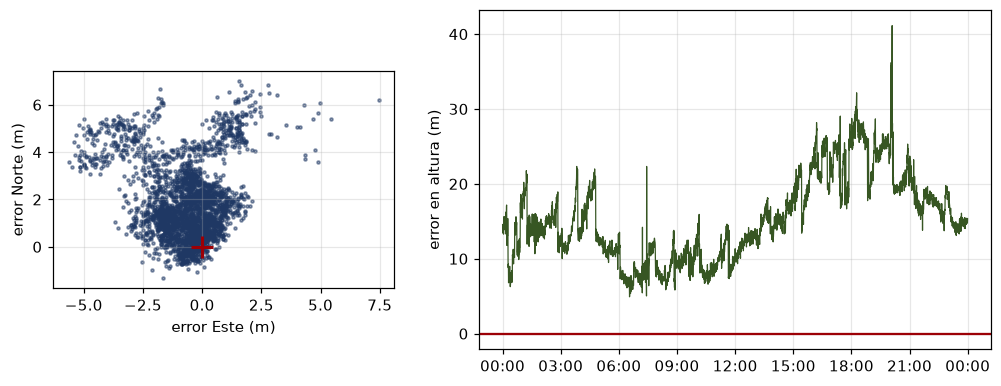

In [44]:
rms_h = np.sqrt((sol.E**2 + sol.N**2).mean())
print(f"{len(sol)} épocas | RMS horizontal {rms_h:.2f} m | error en altura: media {sol.U.mean():+.1f} m, RMS {np.sqrt((sol.U**2).mean()):.1f} m | sigma0 mediana {sol.sigma0.median():.2f} m")

fig, axs = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw=dict(width_ratios=[1, 1.5]))
axs[0].scatter(sol.E, sol.N, s=4, color=AZUL, alpha=0.5)
axs[0].plot(0, 0, "+", color=ROJO, ms=14, mew=2)
axs[0].set_aspect("equal")
axs[0].set_xlabel("error Este (m)")
axs[0].set_ylabel("error Norte (m)")
axs[0].grid(alpha=0.3)
axs[1].plot(sol.index, sol.U, color=VERDE, lw=0.8)
axs[1].axhline(0, color=ROJO)
axs[1].set_ylabel("error en altura (m)")
axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axs[1].grid(alpha=0.3);

## 10. No todas las medidas valen lo mismo: mínimos cuadrados ponderados

Agrupando los residuos de todas las soluciones del día por elevación, la dispersión crece hacia el horizonte. Tratar todas las medidas por igual es regalar influencia a las peores.

> **Mínimos cuadrados ponderados** — a cada medida se le da un peso $w_i \propto 1/\sigma_i^2$ y se minimiza $\sum w_i v_i^2$. Con $\mathbf{W} = \mathrm{diag}(w_i)$:
> $$\Delta\mathbf{x} = (\mathbf{A}^{\top}\mathbf{W}\mathbf{A})^{-1}\mathbf{A}^{\top}\mathbf{W}\,\Delta\boldsymbol{\rho}, \qquad \hat\sigma_0^2 = \frac{\mathbf{v}^{\top}\mathbf{W}\mathbf{v}}{n-4}$$
> Un modelo habitual: $w_i = \operatorname{sen}^2(\text{elevación}_i)$ (cenit 1; 30° → 0,25; 10° → 0,03).

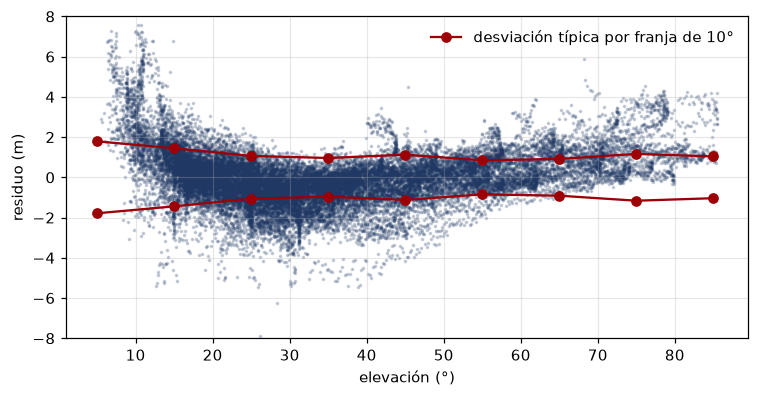

In [45]:
res_el = []                                        # pares (elevación, residuo) de todas las soluciones del día
for t, g in D.groupby("t"):
    if len(g) < 5 or t == t_mala:
        continue
    S_ = g[["xs", "ys", "zs"]].values
    P_ = g.P1.values + C * g.dts.values
    x_, A_, v_, Q_, h_ = resolver(S_, P_)
    res_el += list(zip(g.el.values, v_))
res_el = np.array(res_el)

# desviación típica de los residuos por franja de 10° de elevación
bins = np.arange(0, 91, 10)
franja = np.digitize(res_el[:, 0], bins)
sd = [res_el[franja == i, 1].std() if (franja == i).sum() > 20 else np.nan for i in range(1, len(bins))]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(res_el[:, 0], res_el[:, 1], s=2, color=AZUL, alpha=0.2)
ax.plot(bins[:-1] + 5, sd, "o-", color=ROJO, label="desviación típica por franja de 10°")
ax.plot(bins[:-1] + 5, -np.array(sd), "o-", color=ROJO)
ax.set_ylim(-8, 8)
ax.set_xlabel("elevación (°)")
ax.set_ylabel("residuo (m)")
ax.legend(frameon=False)
ax.grid(alpha=0.3);

In [46]:
W = np.diag(np.sin(np.radians(ep.el.values)) ** 2)      # matriz de pesos: sen²(elevación) en la diagonal
xw, Aw, vw, Qw, hw = resolver(S, P, W=W)
print("pesos:", dict(zip(ep.sv, np.diag(W).round(2).tolist())))
print(f"error 12:00 sin pesos: {enu(x).round(2)} m | con pesos sen²(el): {enu(xw).round(2)} m")

# lo mismo en todo el día
filas = []
for t, g in D.groupby("t"):
    if len(g) < 4 or t == t_mala:
        continue
    S_ = g[["xs", "ys", "zs"]].values
    P_ = g.P1.values + C * g.dts.values
    W_ = np.diag(np.sin(np.radians(g.el.values)) ** 2)
    x_, _, _, _, _ = resolver(S_, P_, W=W_)
    e_ = enu(x_)
    filas.append(dict(t=t, Ew=e_[0], Nw=e_[1], Uw=e_[2]))
solw = pd.DataFrame(filas).set_index("t")

rms_hw = np.sqrt((solw.Ew**2 + solw.Nw**2).mean())
print(f"RMS horizontal del día: sin pesos {rms_h:.2f} m, con pesos {rms_hw:.2f} m | RMS altura: {np.sqrt((sol.U**2).mean()):.1f} -> {np.sqrt((solw.Uw**2).mean()):.1f} m")

pesos: {'G05': 0.14, 'G11': 0.25, 'G12': 0.14, 'G13': 0.11, 'G15': 0.87, 'G20': 0.53, 'G24': 0.42, 'G25': 0.09, 'G29': 0.54}
error 12:00 sin pesos: [ 0.82  0.9  11.34] m | con pesos sen²(el): [0.69 1.19 9.43] m
RMS horizontal del día: sin pesos 2.90 m, con pesos 2.32 m | RMS altura: 16.4 -> 13.3 m


## 11. Propagar la incertidumbre: la covarianza de la solución

> Si cada medida tiene error aleatorio de desviación típica $\sigma_0$, la solución hereda una incertidumbre que se **calcula**, no se supone:
> $$\boldsymbol{\Sigma}_{\mathbf{x}} = \sigma_0^2\,(\mathbf{A}^{\top}\mathbf{W}\mathbf{A})^{-1} = \sigma_0^2\,\mathbf{Q}$$
> $\mathbf{Q}$ es la **matriz cofactor**: depende solo de la geometría. La diagonal de $\boldsymbol{\Sigma}$ son las varianzas de $x, y, z, b$; fuera de la diagonal, las covarianzas. Girada a ENU, da $\sigma_E, \sigma_N, \sigma_U$ y la **elipse de error** horizontal.

sigma0 = 0.82 m
Q_ENU =
 [[ 0.574 -0.127  0.121  0.057]
 [-0.127  0.355 -0.501 -0.309]
 [ 0.121 -0.501  3.26   1.838]
 [ 0.057 -0.309  1.838  1.15 ]]
σ_E, σ_N, σ_U, σ_b = [0.62 0.49 1.48 0.88] m


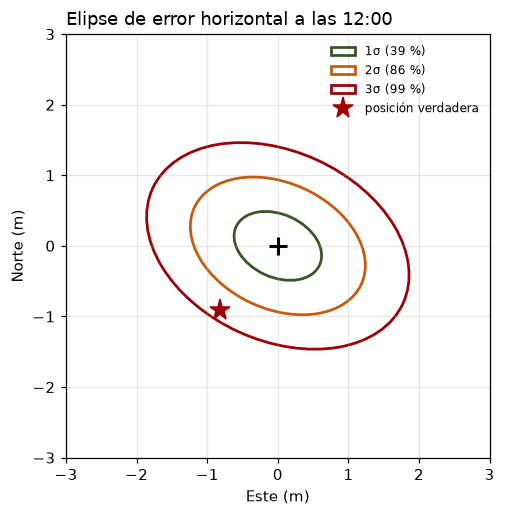

In [47]:
def covarianza_enu(Q):
    """Gira la matriz cofactor Q (en X, Y, Z, b) al sistema local (E, N, U, b)."""
    T = np.block([[Rm, np.zeros((3, 1))],
                  [np.zeros((1, 3)), np.ones((1, 1))]])
    return T @ Q @ T.T

sigma0 = np.sqrt(v @ v / (n - 4))        # desviación típica estimada de una medida (n − 4 grados de libertad)
Qenu = covarianza_enu(Q)
Sigma = sigma0**2 * Qenu                  # matriz de covarianza de la solución
print(f"sigma0 = {sigma0:.2f} m")
print("Q_ENU =\n", Qenu.round(3))
print("σ_E, σ_N, σ_U, σ_b =", np.sqrt(np.diag(Sigma)).round(2), "m")

# elipse de error horizontal: ejes = raíces de los autovalores del bloque E-N; orientación = autovector
from matplotlib.patches import Ellipse
autoval, autovec = np.linalg.eigh(Sigma[:2, :2])
angulo = np.degrees(np.arctan2(autovec[1, 1], autovec[0, 1]))
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_aspect("equal")
for k, color, etiqueta in [(1, VERDE, "1σ (39 %)"), (2, NARANJA, "2σ (86 %)"), (3, ROJO, "3σ (99 %)")]:
    ax.add_patch(Ellipse((0, 0), 2 * k * np.sqrt(autoval[1]), 2 * k * np.sqrt(autoval[0]), angle=angulo, fill=False, ec=color, lw=1.8, label=etiqueta))
ax.plot(0, 0, "+", color="k", ms=12, mew=2)                       # la solución
ax.plot(-E_, -N_, "*", color=ROJO, ms=14, label="posición verdadera")
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
ax.legend(fontsize=8, frameon=False)
ax.grid(alpha=0.3)
ax.set_title("Elipse de error horizontal a las 12:00", loc="left");

## 12. DOP: la geometría como amplificador del error

> **Dilución de la precisión (DOP)** — como $\boldsymbol{\Sigma} = \sigma_0^2\mathbf{Q}$, la incertidumbre de la posición es la de una medida multiplicada por un factor que solo depende de la geometría. Con $q$ los elementos de la diagonal de $\mathbf{Q}_{ENU}$:
> $$\text{GDOP} = \sqrt{q_{EE}+q_{NN}+q_{UU}+q_{bb}},\quad \text{PDOP} = \sqrt{q_{EE}+q_{NN}+q_{UU}},\quad \text{HDOP} = \sqrt{q_{EE}+q_{NN}},\quad \text{VDOP} = \sqrt{q_{UU}},\quad \text{TDOP} = \sqrt{q_{bb}}$$
> Sin unidades. Se calcula **antes de medir**, solo con las posiciones de los satélites; el DOP crece cuando los satélites se agrupan y se dispara cuando quedan casi en un plano.

In [48]:
def dops(Q):
    """Diluciones de la precisión a partir de la matriz cofactor Q (en X, Y, Z, b)."""
    q = np.diag(covarianza_enu(Q))       # varianzas cofactor en E, N, U, b
    return dict(GDOP=np.sqrt(q.sum()),
                PDOP=np.sqrt(q[:3].sum()),
                HDOP=np.sqrt(q[:2].sum()),
                VDOP=np.sqrt(q[2]),
                TDOP=np.sqrt(q[3]))

d = dops(Q)
print({k: round(float(valor), 2) for k, valor in d.items()})
print(f"incertidumbre esperada: horizontal HDOP·σ0 = {d['HDOP']*sigma0:.2f} m, vertical VDOP·σ0 = {d['VDOP']*sigma0:.2f} m")

{'GDOP': 2.31, 'PDOP': 2.05, 'HDOP': 0.96, 'VDOP': 1.81, 'TDOP': 1.07}
incertidumbre esperada: horizontal HDOP·σ0 = 0.79 m, vertical VDOP·σ0 = 1.48 m


mejor PDOP 1.42 a las 20:06 (10 satélites) | peor PDOP 2.87 a las 00:23 (7 satélites)


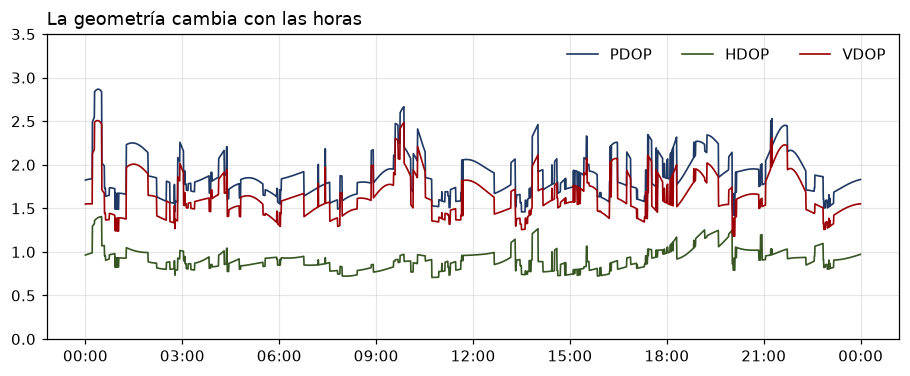

In [49]:
# el DOP solo necesita la geometría: se calcula con A en la posición publicada, sin resolver nada
filas = []
for t, g in D.groupby("t"):
    if len(g) < 4 or t == t_mala:
        continue
    A_, _ = diseno(np.r_[rx, 0.0], g[["xs", "ys", "zs"]].values, g.P1.values)
    d_ = dops(np.linalg.inv(A_.T @ A_))
    d_["t"] = t
    d_["n"] = len(g)
    filas.append(d_)
dop = pd.DataFrame(filas).set_index("t")

fig, ax = plt.subplots(figsize=(10, 3.6))
for nombre, color in [("PDOP", AZUL), ("HDOP", VERDE), ("VDOP", ROJO)]:
    ax.plot(dop.index, dop[nombre], lw=1.1, label=nombre, color=color)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_ylim(0, 3.5)
ax.legend(ncol=3, frameon=False)
ax.grid(alpha=0.3)
ax.set_title("La geometría cambia con las horas", loc="left")

t_mejor, t_peor = dop.PDOP.idxmin(), dop.PDOP.idxmax()
print(f"mejor PDOP {dop.PDOP.min():.2f} a las {t_mejor.strftime('%H:%M')} ({dop.loc[t_mejor, 'n']} satélites) | peor PDOP {dop.PDOP.max():.2f} a las {t_peor.strftime('%H:%M')} ({dop.loc[t_peor, 'n']} satélites)")

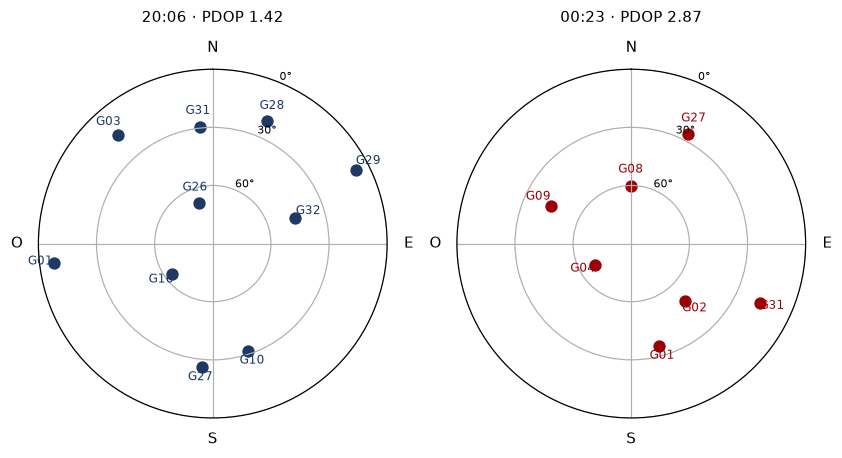

In [50]:
def cielo(ax, g, color, titulo):
    """Dibuja el cielo (acimut y elevación) de los satélites de una época en un eje polar."""
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_rlim(0, 90)
    ax.set_yticks([0, 30, 60, 90]); ax.set_yticklabels(["90°", "60°", "30°", "0°"], fontsize=7)
    ax.set_xticks(np.radians([0, 90, 180, 270])); ax.set_xticklabels(["N", "E", "S", "O"])
    ax.scatter(np.radians(g.az), 90 - g.el, s=50, color=color)     # el radio es 90° − elevación: el cenit queda en el centro
    for az_, el_, sv_ in zip(g.az, g.el, g.sv):
        ax.text(np.radians(az_), 90 - el_ + 7, sv_, ha="center", fontsize=8, color=color)
    ax.set_title(titulo, fontsize=10, pad=12)

fig = plt.figure(figsize=(9, 4.3))
for k, (t_, color) in enumerate([(t_mejor, AZUL), (t_peor, ROJO)]):
    cielo(fig.add_subplot(1, 2, k + 1, projection="polar"), D[D.t == t_], color, f"{t_.strftime('%H:%M')} · PDOP {dop.loc[t_, 'PDOP']:.2f}")

## 13. Degradar a propósito: elegir satélites bien o mal

Con nueve satélites hay 126 maneras de quedarse con cuatro. El mejor cuarteto (uno alto y tres bajos repartidos) tiene un GDOP parecido al de los nueve; el peor deja los cuatro casi en un plano y la matriz $\mathbf{A}^{\top}\mathbf{A}$ cerca de ser singular: mismas medidas, error de cientos de metros.

Quitar los satélites bajos empeora el DOP (sobre todo el VDOP) y sin embargo puede reducir el error real en altura: el DOP amplifica el **ruido aleatorio**, pero los satélites bajos traen además el mayor **retraso atmosférico**, un sesgo que el DOP no ve. Por eso los receptores usan una **máscara de elevación** (típicamente 5–15°) y corrigen la atmósfera con modelos.

In [51]:
import itertools
cuartetos = []
for idx in itertools.combinations(range(n), 4):        # todas las maneras de elegir 4 de los n satélites
    idx = list(idx)
    try:
        x4, A4, v4, Q4, _ = resolver(S[idx], P[idx])
        cuartetos.append(dict(svs=" ".join(ep.sv[idx]), GDOP=dops(Q4)["GDOP"], error_3D=np.linalg.norm(enu(x4))))
    except np.linalg.LinAlgError:                       # geometría singular: no hay solución
        pass
cu = pd.DataFrame(cuartetos).sort_values("GDOP")
print("mejor cuarteto:\n", cu.head(3).round(1).to_string(index=False))
print("\npeor cuarteto:\n", cu.tail(3).round(1).to_string(index=False))
print("\nGDOP mediano de los", len(cu), "cuartetos:", round(cu.GDOP.median(), 1))

mejor cuarteto:
             svs  GDOP  error_3D
G05 G11 G15 G25   2.8      10.1
G05 G15 G24 G25   2.9      10.6
G05 G11 G13 G15   3.2       9.1

peor cuarteto:
             svs  GDOP  error_3D
G12 G15 G24 G25 451.1      14.0
G05 G12 G13 G29 623.5      84.2
G05 G11 G12 G25 641.3     421.2

GDOP mediano de los 126 cuartetos: 6.7


In [52]:
casos = [("los nueve", np.ones(n, bool)),
         ("solo elevación > 25°", ep.el.values > 25),
         ("solo elevación > 40°", ep.el.values > 40)]
for nombre, mascara in casos:
    idx = np.where(mascara)[0]
    xq, Aq, vq, Qq, _ = resolver(S[idx], P[idx])
    dq = dops(Qq)
    print(f"{nombre:<22} n={len(idx)}  HDOP {dq['HDOP']:.2f}  VDOP {dq['VDOP']:.2f}  error E,N,U = {enu(xq).round(1)} m")

los nueve              n=9  HDOP 0.96  VDOP 1.81  error E,N,U = [ 0.8  0.9 11.3] m
solo elevación > 25°   n=5  HDOP 1.80  VDOP 5.21  error E,N,U = [-0.6  1.2  5.9] m
solo elevación > 40°   n=4  HDOP 2.05  VDOP 5.74  error E,N,U = [0.5 1.5 2.8] m


## 14. Qué debe reportar una solución

Una posición sin su incertidumbre no es un resultado. El informe mínimo de una época:

In [53]:
reporte = {
    "época (tiempo GPS)": str(t0),
    "satélites usados": list(ep.sv),
    "pesos": "iguales",
    "X, Y, Z (m)": x[:3].round(3).tolist(),
    "b = c·δt_R (m)": round(x[3], 3),
    "sigma0 (m)": round(sigma0, 3),
    "residuos (m)": v.round(2).tolist(),
    "σ_E, σ_N, σ_U (m)": np.sqrt(np.diag(Sigma))[:3].round(2).tolist(),
    **{k: round(float(valor), 2) for k, valor in d.items()},
    "error respecto a la posición publicada E, N, U (m)": enu(x).round(2).tolist(),
    "correcciones aplicadas": "reloj del satélite (a0, a1, a2, relativista, T_GD); atmósfera: ninguna",
}
for clave, valor in reporte.items():
    print(f"{clave:<52} {valor}")

época (tiempo GPS)                                   2026-09-15 12:00:00
satélites usados                                     ['G05', 'G11', 'G12', 'G13', 'G15', 'G20', 'G24', 'G25', 'G29']
pesos                                                iguales
X, Y, Z (m)                                          [1744402.911, -6116048.132, 512733.571]
b = c·δt_R (m)                                       12.998
sigma0 (m)                                           0.818
residuos (m)                                         [0.09, 0.57, -0.19, -0.28, 1.11, -0.69, -0.5, 0.63, -0.74]
σ_E, σ_N, σ_U (m)                                    [0.62, 0.49, 1.48]
GDOP                                                 2.31
PDOP                                                 2.05
HDOP                                                 0.96
VDOP                                                 1.81
TDOP                                                 1.07
error respecto a la posición publicada E, N, U (m)   [0.82, 0.9

## 15. Ejercicios (base del trabajo en clase)

Con una época distinta a las 12:00:00, entregar con cifras y una figura por punto:

1. La solución con todos los satélites: posición, $b$, $\hat\sigma_0$, residuos, DOP y error E, N, U respecto a la posición publicada.
2. Quitar satélites: el cuarteto de menor y de mayor GDOP de esa época, con el error que produce cada uno.
3. Empeorar la geometría: dejar solo los satélites de un lado del cielo (por acimut) y explicar qué componente del error crece y por qué.
4. Cambiar la ponderación: pesos iguales, $\operatorname{sen}^2(el)$ y una alternativa propia; comparar $\sigma_E, \sigma_N, \sigma_U$.
5. Una medida corrupta: sumar 300 m a la pseudodistancia de un satélite y mostrar cómo lo delatan los residuos y qué le pasa a la solución.

En todos los puntos, explicar qué le pasa a la **covarianza** y distinguir lo que el DOP predice de lo que no.

## Referencias

- Blewitt, G. (1997). *Basics of the GPS Technique: Observation Equations, Software Developments, and Data Processing*. En Teunissen y Kleusberg (eds.), GPS for Geodesy. Springer.
- Leick, A., Rapoport, L. y Tatarnikov, D. (2015). *GPS Satellite Surveying*, 4.ª ed. Wiley.
- Groves, P. D. (2013). *Principles of GNSS, Inertial, and Multisensor Integrated Navigation Systems*, 2.ª ed. Artech House.
- IS-GPS-200, *Navstar GPS Space Segment/Navigation User Segment Interfaces* (gps.gov/technical/icwg).
- Legendre, A.-M. (1805). *Nouvelles méthodes pour la détermination des orbites des comètes* · Gauss, C. F. (1809). *Theoria motus corporum coelestium*.
- IGS, International GNSS Service (igs.org): datos de la estación BOGT.